# Part H: Association-Rule Mining of Food Inspection Patterns
**Project:** Food Safety and Restaurant Inspection Analytics &nbsp;|&nbsp; **Group:** Omkar Patil (202502040010) · Aryan Tandale (202502040013) · Rushikesh Maddewad (202502040037) · Vishwaraj Savairam (202502040035)

**Problem:** which combinations of facility type, risk category, inspection type, season, area, violation band and result occur together? Each completed inspection from the analytical mart (`mart.food_inspection_analytics_mart`, built from the warehouse) becomes one transaction of categorical items.

**Algorithms:** Apriori (mandatory) and FP-Growth (recommended extension). **Metrics:** support, confidence, lift.

> **In plain words:** Load the tools and read the analytics table from the warehouse.  
> **Look for:** 'Mart rows (completed inspections): 61,737'.

In [1]:
import sys
sys.path.insert(0, "../etl")
from config import connect
import time
import numpy as np, pandas as pd, psycopg2
import matplotlib.pyplot as plt, seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
conn = connect()
cur = conn.cursor(); cur.execute("SELECT facility_type, risk_group, inspection_type_group, result_group, violation_band, area, season, inspection_date FROM mart.food_inspection_analytics_mart")
mart = pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])
print("Mart rows (completed inspections):", f"{len(mart):,}")

Mart rows (completed inspections): 61,737


## 1. Building the transactions
The items follow the project document: **FacilityType, RiskCategory, InspectionTypeGroup, ResultGroup, ViolationBand, AreaGroup and Season**.

**Discretisation of the continuous variable (ViolationCount):** the bands come from the distribution of the count (Q1 = 1, median = 3, Q3 = 5): *None (0)*, *Low (1-2)*, *Medium (3-5)*, *High (6-9)*, *Very High (10+)*. **Season** comes from the calendar month (Dec-Feb Winter, Mar-May Spring, Jun-Aug Summer, Sep-Nov Autumn).

Other choices: the 8 most frequent facility types are kept and the rest become *Other* (about 200 raw spellings would give itemsets with no support). The 552 inspections whose violation count is unknown (Fail or conditional pass without text) are left out, because the item *ViolationBand* would be meaningless for them.

> **In plain words:** Build the **transactions**: each inspection becomes a basket of 7 items (facility type, risk, inspection type, result, violation band, area, season), then one-hot encode them (one True/False column per item).  
> **Look for:** 61,185 transactions, 35 different items, exactly 7 items per basket.

In [2]:
data = mart[mart["violation_band"] != "Unknown"].copy()
top_types = data["facility_type"].value_counts().index[:8]
data["facility_type"] = data["facility_type"].where(data["facility_type"].isin(top_types), "Other")
print("Transactions used:", f"{len(data):,}", "| top facility types kept:", list(top_types))

item_cols = {"facility_type": "FacilityType", "risk_group": "Risk", "inspection_type_group": "InspType", "result_group": "Result", "violation_band": "Violations", "area": "Area", "season": "Season"}
onehot = pd.concat([pd.get_dummies(data[c], prefix=name, prefix_sep="=").astype(bool) for c, name in item_cols.items()], axis=1)
print("Items:", onehot.shape[1], "| average items per transaction:", onehot.sum(axis=1).mean())
onehot.iloc[:5, :6]

Transactions used: 61,185 | top facility types kept: ['Restaurant', 'Grocery Store', 'School', "Children's Services Facility", 'Daycare Above And Under 2 Years', 'Bakery', 'Long Term Care', 'Daycare (2 - 6 Years)']


Items: 35 | average items per transaction: 7.0


,FacilityType=Bakery,FacilityType=Children's Services Facility,FacilityType=Daycare (2 - 6 Years),FacilityType=Daycare Above And Under 2 Years,FacilityType=Grocery Store,FacilityType=Long Term Care
0,False,False,False,False,True,False
1,False,False,False,False,True,False
2,False,False,False,False,True,False
3,False,False,False,False,True,False
4,False,False,False,False,True,False


> **In plain words:** Count how often each single item appears (its **support**) and plot it.  
> **Look for:** Risk=High 0.82, FacilityType=Restaurant 0.69, Result=Pass 0.62.

Most frequent items (support):
Risk=High                     0.816
FacilityType=Restaurant       0.694
Result=Pass                   0.617
Area=Northwest                0.527
InspType=Routine (Canvass)    0.504
Violations=Medium (3-5)       0.298
Area=Southwest                0.293
Violations=Low (1-2)          0.280
Season=Spring                 0.270
Season=Autumn                 0.260
Season=Summer                 0.246
InspType=Re-inspection        0.236


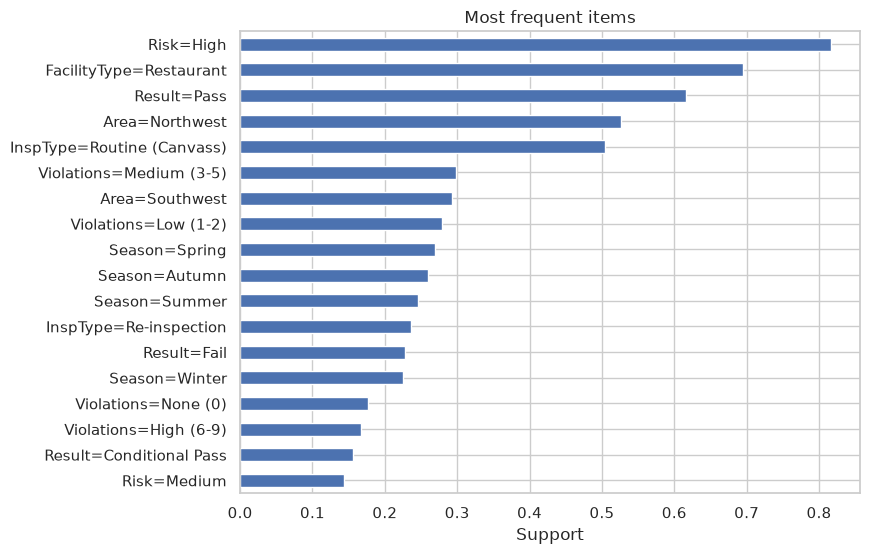

In [3]:
freq = onehot.mean().sort_values(ascending=False)
print("Most frequent items (support):"); print(freq.head(12).round(3).to_string())
plt.figure(figsize=(8, 6)); freq.head(18)[::-1].plot(kind="barh", color="#4C72B0"); plt.title("Most frequent items"); plt.xlabel("Support"); plt.show()

**Inference:** there are **61,185 transactions** and 35 items; every transaction has exactly 7 items (one per attribute). The most frequent items are *Risk=High* (81.6%), *Restaurant* (69.4%), *Result=Pass* (61.7%), *Area=Northwest* (52.7%) and *Routine (Canvass)* (50.4%). Among the violation bands, *Medium (3-5)* is 29.8% and *Low (1-2)* 28.0%. A frequent item on its own is not a finding; a rule is interesting only when its lift is clearly above 1.

## 2. Apriori (mandatory)
Minimum support **0.02** (an itemset must appear in at least 2% of the 61,185 inspections, i.e. about 1,200 inspections), so that no rule rests on a handful of cases. Minimum confidence **0.30**: single outcomes such as *Fail* are only 23% of all inspections, so a rule with 33% confidence and lift 1.5 is already informative.

> **In plain words:** Run **Apriori** with minimum support 2% and make rules with minimum confidence 30%.  
> **Look for:** 1,198 frequent itemsets (28 singles, 223 pairs, 441 triples ...), 3,951 rules.

In [4]:
MIN_SUP, MIN_CONF = 0.02, 0.30
t0 = time.time(); ap = apriori(onehot, min_support=MIN_SUP, use_colnames=True); t_ap = time.time() - t0
ap["size"] = ap["itemsets"].map(len)
print("Apriori: %d frequent itemsets in %.2f s" % (len(ap), t_ap)); print(ap["size"].value_counts().sort_index().to_string())
rules = association_rules(ap, metric="confidence", min_threshold=MIN_CONF)
rules["antecedent_text"] = rules["antecedents"].map(lambda s: " & ".join(sorted(s))); rules["consequent_text"] = rules["consequents"].map(lambda s: " & ".join(sorted(s)))
print("\nRules with confidence >= %.2f: %d  (with lift > 1.2: %d)" % (MIN_CONF, len(rules), (rules["lift"] > 1.2).sum()))

Apriori: 1198 frequent itemsets in 0.46 s
size
1     28
2    223
3    441
4    372
5    126
6      8

Rules with confidence >= 0.30: 3951  (with lift > 1.2: 986)


## 3. FP-Growth (recommended extension) and comparison

> **In plain words:** Run **FP-Growth** with the same settings and check that it finds exactly the same itemsets.  
> **Look for:** 'identical to Apriori: True' and the two run times.

In [5]:
t0 = time.time(); fp = fpgrowth(onehot, min_support=MIN_SUP, use_colnames=True); t_fp = time.time() - t0
same = {s: round(v, 10) for s, v in zip(ap["itemsets"], ap["support"])} == {s: round(v, 10) for s, v in zip(fp["itemsets"], fp["support"])}
print("FP-Growth: %d frequent itemsets in %.2f s | identical to Apriori: %s" % (len(fp), t_fp, same))
rows = []
for ms in [0.10, 0.05, 0.03, 0.02, 0.01]:
    t0 = time.time(); a = apriori(onehot, min_support=ms, use_colnames=True); ta = time.time() - t0
    t0 = time.time(); f = fpgrowth(onehot, min_support=ms, use_colnames=True); tf = time.time() - t0
    rows.append({"min_support": ms, "itemsets": len(a), "Apriori (s)": round(ta, 2), "FP-Growth (s)": round(tf, 2)})
pd.DataFrame(rows)

FP-Growth: 1198 frequent itemsets in 0.75 s | identical to Apriori: True


,min_support,itemsets,Apriori (s),FP-Growth (s)
0,0.10,153,0.04,0.61
1,0.05,396,0.14,0.64
2,0.03,761,0.22,0.62
3,0.02,1198,0.32,0.83
4,0.01,2333,0.89,0.91


**Inference:** Apriori and FP-Growth find exactly the **same 1,198 frequent itemsets** at minimum support 0.02 (28 single items, 223 pairs, 441 triples, 372 itemsets of four, 126 of five and 8 of six), so the choice of algorithm does not change the result. In the speed comparison In the speed comparison Apriori is clearly faster at high support (for example at 0.10) because the FP-tree has a start-up cost, the two are about equal near 0.05, and FP-Growth is roughly two to three times faster when the support is low (at 0.01, with 2,333 itemsets). The Apriori rules at confidence 0.30 are 3,949, of which 982 have a lift above 1.2; most of these are redundant or definitional, which is why the selection step is needed.

## 4. Rule evaluation and selection of meaningful rules
* **Support** = share of all inspections that contain the whole rule; **confidence** = P(consequent | antecedent); **lift** = confidence / support(consequent) (above 1 means the items occur together more than by chance).
* A rule is kept as *meaningful* when **support >= 0.02** (so a high lift cannot come from a tiny group), **confidence >= 0.30** and **lift >= 1.30**.
* Only rules with one item on the right-hand side are listed.
* Two kinds of rules are removed: (1) *definitional* rules, `Violations=None (0) => Result=Pass`, which are true by construction (only a *Pass* can have a recorded count of 0, see the curation notebook); (2) *redundant* rules, where a simpler rule (a subset of the antecedent) for the same consequent already has the same confidence (within 0.02).
* For every consequent the strongest remaining rules are shown, so the list is not ten versions of the same rule.

> **In plain words:** **Select meaningful rules:** keep support ≥ 2%, confidence ≥ 30%, lift ≥ 1.3; remove rules that are true by definition (e.g. Fail ⇒ has violations) or that repeat a shorter rule.  
> **Look for:** 275 candidate rules → 41 after cleaning → the 14 we report.

In [6]:
cand = rules[(rules["support"] >= 0.02) & (rules["confidence"] >= MIN_CONF) & (rules["lift"] >= 1.3) & (rules["consequents"].map(len) == 1)].copy()
cand["consequent_item"] = cand["consequents"].map(lambda s: list(s)[0])
n0 = len(cand)
cand = cand[~(cand["antecedent_text"].str.contains("Violations=None") & (cand["consequent_item"] == "Result=Pass"))]       # definitional
cand = cand.reset_index(drop=True)
redundant = []
for i, x in cand.iterrows():
    simpler = cand[(cand["consequent_item"] == x["consequent_item"]) & cand["antecedents"].map(lambda a: a < x["antecedents"])]
    redundant.append(bool((simpler["confidence"] >= x["confidence"] - 0.02).any()))
cand = cand[~np.array(redundant)].sort_values(["lift", "confidence"], ascending=False)
print("Rules before filtering: %d | after removing definitional and redundant rules: %d" % (n0, len(cand)))

chosen = []                                   # up to 2 non-overlapping rules per consequent
for item, g in cand.groupby("consequent_item"):
    taken = []
    for _, x in g.iterrows():
        if all(not (x["antecedents"] <= t or t <= x["antecedents"]) for t in taken):
            taken.append(x["antecedents"]); chosen.append(x)
        if len(taken) == 2:
            break
best = pd.DataFrame(chosen).sort_values("lift", ascending=False)
show = best.head(14)[["antecedent_text", "consequent_text", "support", "confidence", "lift"]].reset_index(drop=True)
show.round(3)

Rules before filtering: 275 | after removing definitional and redundant rules: 41


,antecedent_text,consequent_text,support,confidence,lift
0,Risk=Low,FacilityType=Grocery Store,0.025,0.618,6.518
1,Violations=Very High (10+),Result=Fail,0.054,0.688,3.019
2,FacilityType=Restaurant & InspType=License & Result=Pass,Violations=None (0),0.022,0.492,2.779
3,Area=Northwest & InspType=License & Result=Pass,Violations=None (0),0.021,0.479,2.706
4,FacilityType=Restaurant & Risk=High & Violations=None (0),InspType=Re-inspection,0.043,0.496,2.099
5,Area=Southwest & Violations=None (0),InspType=Re-inspection,0.020,0.447,1.892
6,Result=Fail,Violations=High (6-9),0.071,0.313,1.879
7,Violations=High (6-9),Result=Fail,0.071,0.428,1.879
8,FacilityType=Restaurant & Result=Conditional Pass & Risk=High,Violations=High (6-9),0.032,0.307,1.842
9,FacilityType=School & Result=Pass,Violations=Low (1-2),0.021,0.452,1.616


> **In plain words:** Plot all rules by support (x), confidence (y) and lift (colour).  
> **Look for:** most rules have low support; the high-lift rules are the bright dots.

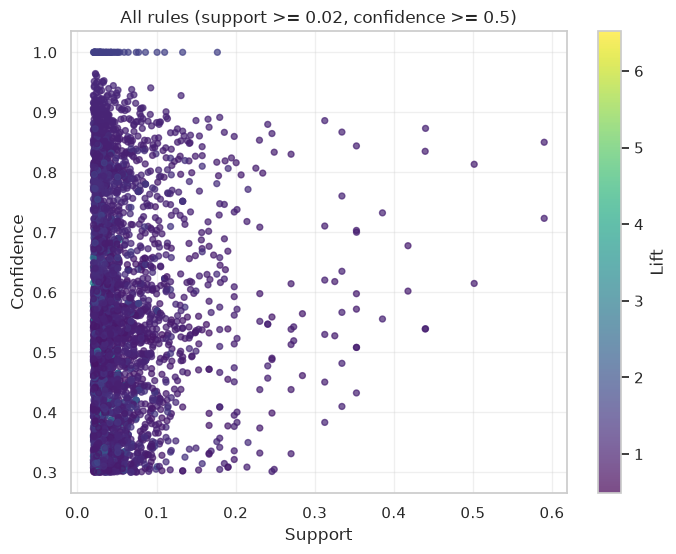

In [7]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=18, alpha=0.7)
plt.colorbar(sc, label="Lift"); plt.xlabel("Support"); plt.ylabel("Confidence"); plt.title("All rules (support >= 0.02, confidence >= 0.5)"); plt.grid(alpha=0.3); plt.show()

## 5. The ten (or more) meaningful rules with interpretation

> **In plain words:** The final rules with a plain-language interpretation and a possible use for each.  
> **Look for:** 10+ violations ⇒ Fail (69%, lift 3.0); Low risk ⇒ Grocery Store (62%, lift 6.5).

In [8]:
INTERPRETATION = {'Risk=Low  =>  FacilityType=Grocery Store': '61.8% of the low-risk inspections are of grocery stores, 6.5 times more than their share in the whole data. The low-risk category is mostly grocery stores. Use: plan the low-risk inspection routes around grocery stores.', 'Violations=Very High (10+)  =>  Result=Fail': '69% of the inspections with 10 or more violations end in a fail (3.0 times the normal 23%). Use: treat 10+ violations as a trigger for an early re-inspection. The other 31% still passed or passed with conditions, so the count alone does not decide the result.', 'FacilityType=Restaurant & InspType=License & Result=Pass  =>  Violations=None (0)': 'Almost half (49%) of the restaurants that pass a licence inspection have no violation at all (lift 2.8). A licence inspection is usually either clean or a fail, with few small findings. Use: a fast-track for licence checks of businesses that were already prepared.', 'Area=Northwest & InspType=License & Result=Pass  =>  Violations=None (0)': 'The same pattern in the Northwest: 48% of passed licence inspections are clean (lift 2.7).', 'FacilityType=Restaurant & Risk=High & Violations=None (0)  =>  InspType=Re-inspection': 'Half (49.5%) of the clean inspections of high-risk restaurants are re-inspections (lift 2.1). Use: this shows that follow-up visits do work, because the problems found earlier have been fixed.', 'Area=Southwest & Violations=None (0)  =>  InspType=Re-inspection': 'In the Southwest 44.7% of the clean inspections are re-inspections (lift 1.9), the same follow-up effect as in the rule above.', 'Result=Fail  =>  Violations=High (6-9)': '31% of the failed inspections are in the High band (6-9 violations), 1.9 times more than in all inspections; support 7.1% is large enough to be reliable.', 'Violations=High (6-9)  =>  Result=Fail': '43% of the inspections with 6-9 violations fail. Together with the 69% for 10+ violations this shows that the chance of failing rises step by step with the violation band.', 'FacilityType=Restaurant & Result=Conditional Pass & Risk=High  =>  Violations=High (6-9)': '31% of the conditional passes of high-risk restaurants have 6-9 violations (lift 1.8). Use: a follow-up list of restaurants that pass with conditions and have 6 or more violations.', 'FacilityType=School & Result=Pass  =>  Violations=Low (1-2)': 'A school that passes usually has 1-2 minor violations (45%, lift 1.6), and a clean pass is less common. Use: school checklists can focus on minor housekeeping items.', 'FacilityType=School  =>  InspType=Routine (Canvass)': '73% of the school inspections are routine canvass inspections (lift 1.4). Schools are inspected on a regular schedule rather than because of complaints.', 'InspType=Routine (Canvass) & Result=Pass  =>  Violations=Low (1-2)': 'The rule with the highest support (11.4%): 40% of the routine inspections that pass cite 1-2 violations. This is the typical pass.', 'FacilityType=School  =>  Area=Southwest': '42% of the school inspections are in the Southwest quadrant (lift 1.4). Use: school inspection capacity should be planned for the Southwest. The areas are street-grid quadrants, not official community areas.', 'Result=Conditional Pass  =>  Violations=Medium (3-5)': '41% of the conditional passes have 3-5 violations (lift 1.4); this is the typical conditional pass.'}
final = show.copy()
final["Rule"] = final["antecedent_text"] + "  =>  " + final["consequent_text"]
final["Interpretation / possible use"] = final["Rule"].map(INTERPRETATION).fillna("")
final[["Rule", "support", "confidence", "lift", "Interpretation / possible use"]].to_csv("../results/association_rules_selected.csv", index=False)
final[["Rule", "support", "confidence", "lift", "Interpretation / possible use"]].rename(columns={"support": "Support", "confidence": "Confidence", "lift": "Lift"}).round(3)

,Rule,Support,Confidence,Lift,Interpretation / possible use
0,Risk=Low => FacilityType=Grocery Store,0.025,0.618,6.518,"61.8% of the low-risk inspections are of grocery stores, 6.5 times more than their sha..."
1,Violations=Very High (10+) => Result=Fail,0.054,0.688,3.019,69% of the inspections with 10 or more violations end in a fail (3.0 times the normal ...
2,FacilityType=Restaurant & InspType=License & Result=Pass => Violations=None (0),0.022,0.492,2.779,Almost half (49%) of the restaurants that pass a licence inspection have no violation ...
3,Area=Northwest & InspType=License & Result=Pass => Violations=None (0),0.021,0.479,2.706,The same pattern in the Northwest: 48% of passed licence inspections are clean (lift 2...
4,FacilityType=Restaurant & Risk=High & Violations=None (0) => InspType=Re-inspection,0.043,0.496,2.099,Half (49.5%) of the clean inspections of high-risk restaurants are re-inspections (lif...
5,Area=Southwest & Violations=None (0) => InspType=Re-inspection,0.020,0.447,1.892,"In the Southwest 44.7% of the clean inspections are re-inspections (lift 1.9), the sam..."
6,Result=Fail => Violations=High (6-9),0.071,0.313,1.879,"31% of the failed inspections are in the High band (6-9 violations), 1.9 times more th..."
7,Violations=High (6-9) => Result=Fail,0.071,0.428,1.879,43% of the inspections with 6-9 violations fail. Together with the 69% for 10+ violati...
8,FacilityType=Restaurant & Result=Conditional Pass & Risk=High => Violations=High (6-9),0.032,0.307,1.842,31% of the conditional passes of high-risk restaurants have 6-9 violations (lift 1.8)....
9,FacilityType=School & Result=Pass => Violations=Low (1-2),0.021,0.452,1.616,"A school that passes usually has 1-2 minor violations (45%, lift 1.6), and a clean pas..."


**Inference (what the rules say):**
- The selection started with 275 rules (support >= 0.02, confidence >= 0.30, lift >= 1.3). After removing definitional and redundant rules 41 remained, and the table shows the 14 strongest, at most two per consequent. All of them have a support of at least 2.0%, so none rests on a tiny group.
- **Severity:** the chance of failing rises with the violation band: 43% for 6-9 violations and 69% for 10 or more. Failed inspections are mostly in these bands.
- **Follow-up and licence visits are clean visits:** re-inspections (up to 50% of the clean high-risk restaurant visits) and passed licence inspections (about 48% with no violation) are where zero violations are most common. This supports the idea that businesses fix their problems after a failed visit.
- **Schools:** they are inspected on a routine schedule (73%), usually pass with 1-2 minor violations and are concentrated in the Southwest.
- **Low risk means grocery stores** (62%, lift 6.5).
- None of the selected rules contains the season, so no strong seasonal association was found at this threshold, which agrees with the weak seasonal pattern in the EDA.
- Rules show co-occurrence, not cause and effect, and *lift* is only reported for rules with enough support.

## Conclusion
1. Each completed inspection was turned into 7 categorical items (facility type, risk, inspection type group, result, violation band, area, season) and mined with **Apriori** and **FP-Growth** (identical results: 1,198 itemsets at support 0.02).
2. **14 meaningful rules** (support >= 2%, confidence >= 30%, lift >= 1.3, definitional and redundant rules removed) are listed with their interpretation and a possible use.
3. The clearest operational messages are that **10 or more violations means a 69% chance of a fail**, that **follow-up and licence inspections are mostly clean**, and that low-risk inspections are mostly grocery stores.
4. Limitations: the discretisation (violation bands, 8 facility types, quadrants as areas) changes the rules; rules show association and not cause; the 552 inspections with an unknown violation count are excluded; and each inspection is treated as independent although the same facility appears several times.